<div style="background-color: black; color: gold; padding: 10px; 
            font-size: 24px; border-radius: 5px; text-align: center;">
    Leafwise — Plant Disease Detection with Deep Learning
</div>
<div style=" color: gray; padding: 10px; 
            font-size: 16px; border-radius: 5px; text-align: center;">
    Research notebook: training and evaluating classifiers on the Plant Village dataset
</div>
<br>
<div style="color: gray;  text-align: center; font-size: 14px; margin-top: 10px;">
    <strong>Maintained by:</strong> <a href="https://github.com/janvibuilds/Leafwise" style="color: gold; text-decoration: none;">Leafwise contributors</a> <br>
    <strong>Repository:</strong> <a href="https://github.com/janvibuilds/Leafwise" style="color: gold; text-decoration: none;">github.com/janvibuilds/Leafwise</a> <br>
    <strong>Status:</strong> research artifact — never executed in the production request path <br>
    <strong>Original research:</strong> Ahmed Ayman (Feb 2025)
</div>


### What this notebook is?

The original research and training pipeline behind the Leafwise classifier. It walks through:

1. Loading the Plant Village dataset (38 plant/disease classes)
2. Exploratory analysis and data augmentation
3. A baseline CNN (97.23% validation accuracy)
4. Fine-tuning **EfficientNetB3** on ImageNet weights (**99.53%** validation accuracy — the figures reported in `backend/models/metrics.json`)
5. Evaluation: confusion matrix, per-class predictions, and training curves

### How this relates to the app

This notebook is a **research artifact only** — it is never executed by the Leafwise backend. The model that ships in the product lives in `backend/models/plant_disease_model_tf/`, and its preprocessing, labels, and metrics contracts are documented alongside it (`MODEL_CARD.md`, `preprocessing.json`, `metrics.json`).

> Notebook-reported metrics have **not** been independently reproduced. See the model card for limitations and intended use. Reproduce the local stack with `docs/getting-started.md`.



<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     Import Necessary Libraries
</div>


In [2]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.layers import Dense, Conv2D, MaxPooling2D, Flatten, Dropout
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import Adamax
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import BatchNormalization
from tqdm import tqdm
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from PIL import Image
import warnings
warnings.filterwarnings('ignore')


<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     Load the Data
</div>

In [3]:
train_dir = '/kaggle/input/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/train'
valid_dir = '/kaggle/input/new-plant-diseases-dataset/New Plant Diseases Dataset(Augmented)/New Plant Diseases Dataset(Augmented)/valid'
test_dir = '/kaggle/input/new-plant-diseases-dataset/test/test'


<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
    Collecting file paths and their corresponding labels from training directory

</div>

In [4]:
filenames_train = []
label_train = []
folds = os.listdir(train_dir)
for fold in folds: 
    FoldPath = os.path.join(train_dir, fold)
    files = os.listdir(FoldPath)
    for file in tqdm(files):
        filepath = os.path.join(FoldPath,file)
        filenames_train.append(filepath)
        label_train.append(fold)

100%|██████████| 1859/1859 [00:00<00:00, 672289.29it/s]


<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     Collecting file paths and their corresponding labels from valid directory

</div>

In [5]:
filenames_valid = []
label_valid = []
folds = os.listdir(valid_dir)
for fold in folds:
    FoldPath = os.path.join(valid_dir, fold)
    files = os.listdir(FoldPath)
    for file in tqdm(files):
        filepath = os.path.join(FoldPath,file)
        filenames_valid.append(filepath)
        label_valid.append(fold)

100%|██████████| 465/465 [00:00<00:00, 585515.27it/s]


<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     Creating DataFrames for training and validation data

</div>


In [6]:
df_train = pd.DataFrame({
    'filename': filenames_train,
    'label': label_train
})
df_valid = pd.DataFrame({
    'filename': filenames_valid,
    'label': label_valid
})

 
<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     Explore data
</div>

In [7]:
print(df_train.shape)
print(df_valid.shape)

(70295, 2)
(17572, 2)


In [8]:
df_train.head(5)

,filename,label
0,/kaggle/input/new-plant-diseases-dataset/New P...,Tomato___Late_blight
1,/kaggle/input/new-plant-diseases-dataset/New P...,Tomato___Late_blight
2,/kaggle/input/new-plant-diseases-dataset/New P...,Tomato___Late_blight
3,/kaggle/input/new-plant-diseases-dataset/New P...,Tomato___Late_blight
4,/kaggle/input/new-plant-diseases-dataset/New P...,Tomato___Late_blight


In [9]:
df_train.sample(5)


,filename,label
48938,/kaggle/input/new-plant-diseases-dataset/New P...,Strawberry___healthy
38356,/kaggle/input/new-plant-diseases-dataset/New P...,Apple___Cedar_apple_rust
14669,/kaggle/input/new-plant-diseases-dataset/New P...,Corn_(maize)___Northern_Leaf_Blight
40709,/kaggle/input/new-plant-diseases-dataset/New P...,"Pepper,_bell___healthy"
68063,/kaggle/input/new-plant-diseases-dataset/New P...,"Pepper,_bell___Bacterial_spot"


In [10]:
color = ['#CAE0BC','#780C28','#EAFAEA','#6E8E59']

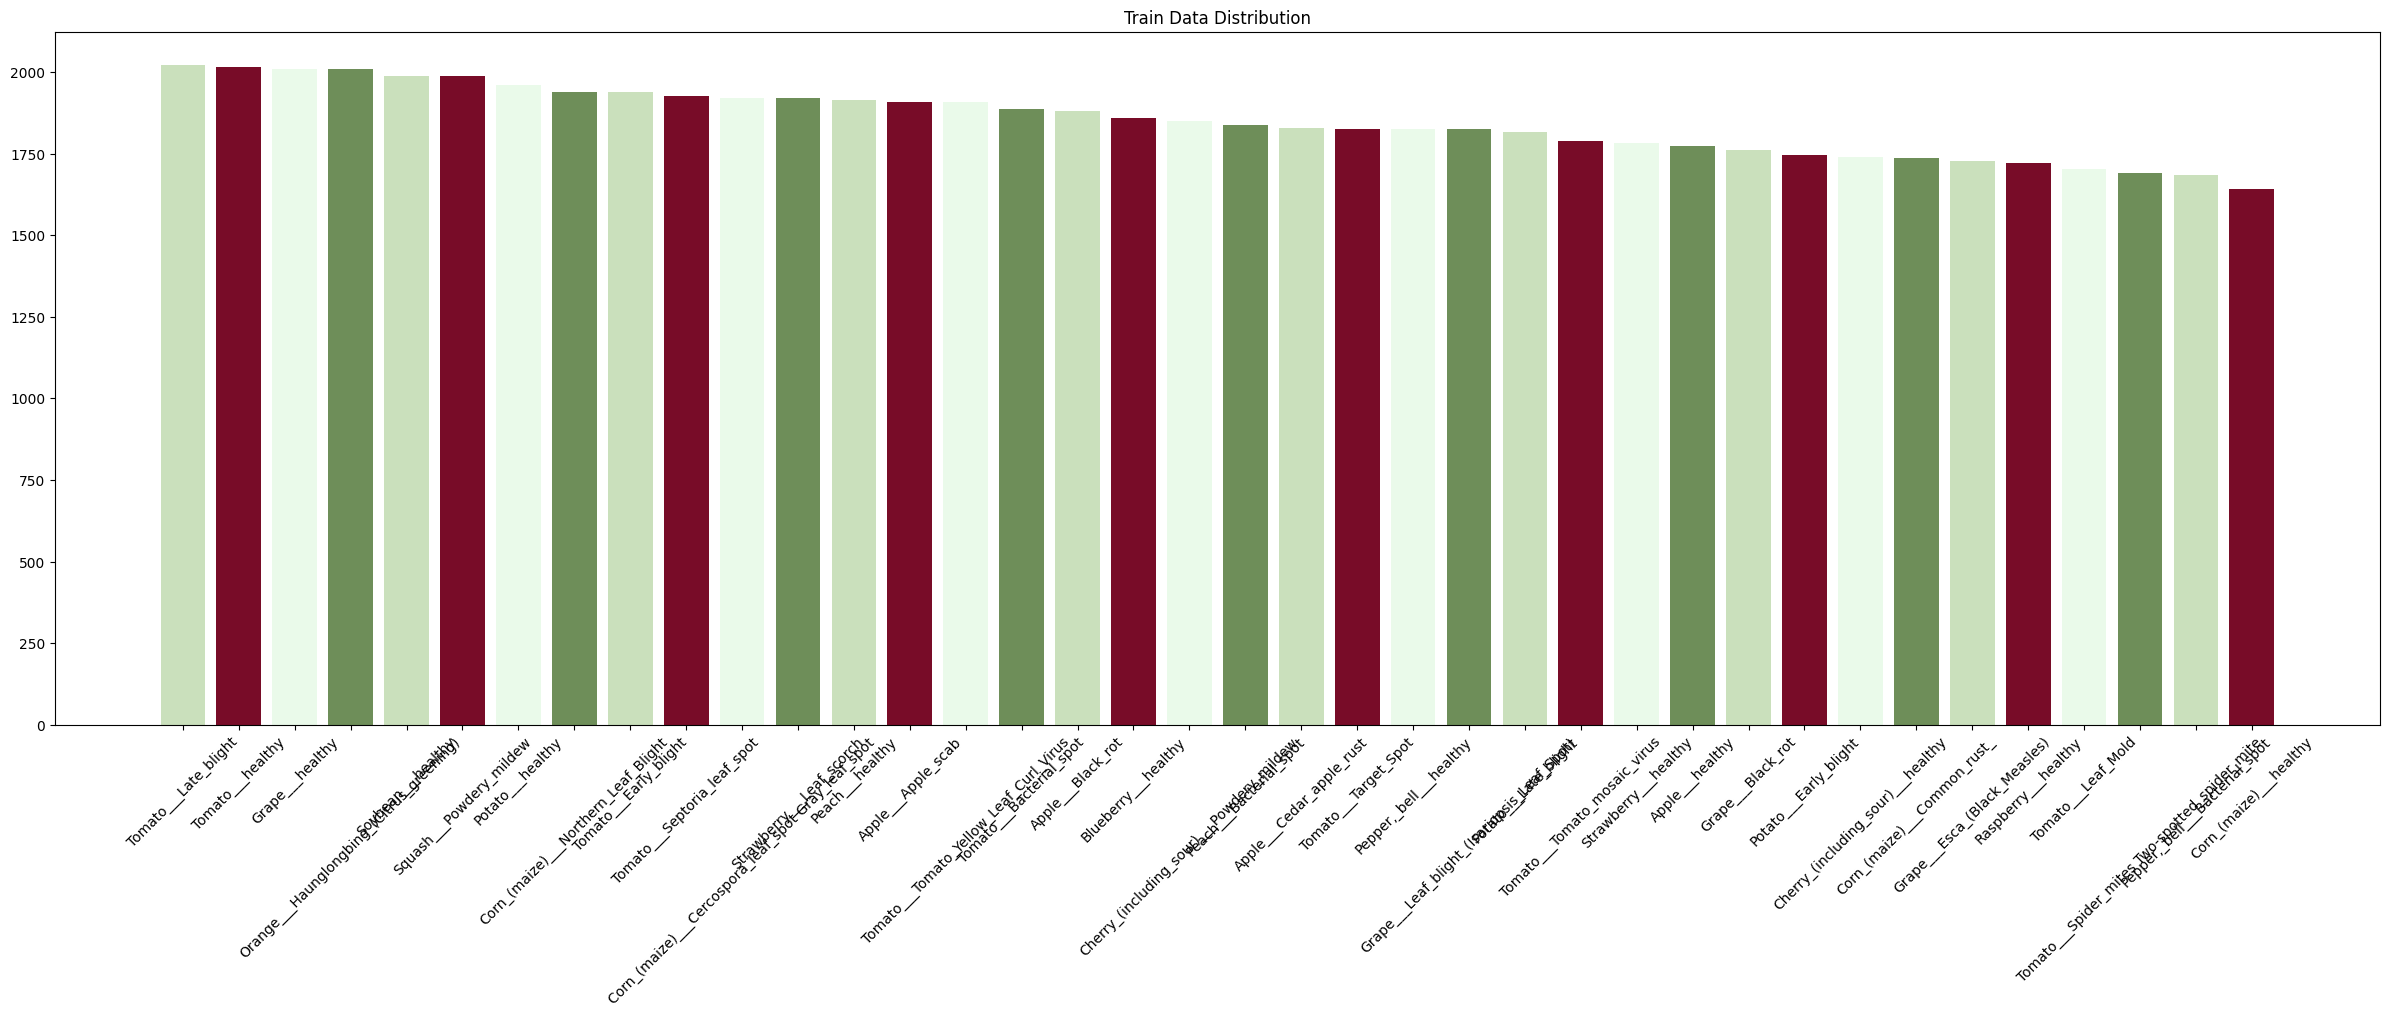

In [11]:
plt.figure(figsize=(30,9))
plt.bar(df_train['label'].unique(), df_train['label'].value_counts(), color=color)
plt.title('Train Data Distribution')
plt.xticks(rotation=45)
plt.show()

In [12]:
print(np.unique(label_train))

['Apple___Apple_scab' 'Apple___Black_rot' 'Apple___Cedar_apple_rust'
 'Apple___healthy' 'Blueberry___healthy'
 'Cherry_(including_sour)___Powdery_mildew'
 'Cherry_(including_sour)___healthy'
 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot'
 'Corn_(maize)___Common_rust_' 'Corn_(maize)___Northern_Leaf_Blight'
 'Corn_(maize)___healthy' 'Grape___Black_rot'
 'Grape___Esca_(Black_Measles)'
 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)' 'Grape___healthy'
 'Orange___Haunglongbing_(Citrus_greening)' 'Peach___Bacterial_spot'
 'Peach___healthy' 'Pepper,_bell___Bacterial_spot'
 'Pepper,_bell___healthy' 'Potato___Early_blight' 'Potato___Late_blight'
 'Potato___healthy' 'Raspberry___healthy' 'Soybean___healthy'
 'Squash___Powdery_mildew' 'Strawberry___Leaf_scorch'
 'Strawberry___healthy' 'Tomato___Bacterial_spot' 'Tomato___Early_blight'
 'Tomato___Late_blight' 'Tomato___Leaf_Mold' 'Tomato___Septoria_leaf_spot'
 'Tomato___Spider_mites Two-spotted_spider_mite' 'Tomato___Target_Spot'
 'Tomato___Tom

<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
      Creating ImageDataGenerator for data augmentation and normalization

</div>

In [13]:
data_gen  = ImageDataGenerator(
    rescale=1./255,
    rotation_range=20,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True)

# only normalization
test_gen = ImageDataGenerator(rescale=1./255)


imge_size = (224,224)
batch_size = 32



<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     Creating data generators from DataFrames for training and validation
</div>


In [14]:
train_gen = data_gen.flow_from_dataframe(
    df_train,
    x_col='filename',
    shuffle=True,
    y_col='label',
    target_size=(imge_size[0],imge_size[1]),
    class_mode='categorical',
    batch_size=batch_size)

valid_gen = data_gen.flow_from_dataframe(
    df_valid,
    shuffle=True,
    x_col='filename',
    y_col='label',
    target_size=(imge_size[0],imge_size[1]),
    class_mode='categorical')



Found 70295 validated image filenames belonging to 38 classes.
Found 17572 validated image filenames belonging to 38 classes.



<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     Retrieving class indices mapping from the training generator
</div>

In [15]:
class_dict = train_gen.class_indices
print(class_dict)

{'Apple___Apple_scab': 0, 'Apple___Black_rot': 1, 'Apple___Cedar_apple_rust': 2, 'Apple___healthy': 3, 'Blueberry___healthy': 4, 'Cherry_(including_sour)___Powdery_mildew': 5, 'Cherry_(including_sour)___healthy': 6, 'Corn_(maize)___Cercospora_leaf_spot Gray_leaf_spot': 7, 'Corn_(maize)___Common_rust_': 8, 'Corn_(maize)___Northern_Leaf_Blight': 9, 'Corn_(maize)___healthy': 10, 'Grape___Black_rot': 11, 'Grape___Esca_(Black_Measles)': 12, 'Grape___Leaf_blight_(Isariopsis_Leaf_Spot)': 13, 'Grape___healthy': 14, 'Orange___Haunglongbing_(Citrus_greening)': 15, 'Peach___Bacterial_spot': 16, 'Peach___healthy': 17, 'Pepper,_bell___Bacterial_spot': 18, 'Pepper,_bell___healthy': 19, 'Potato___Early_blight': 20, 'Potato___Late_blight': 21, 'Potato___healthy': 22, 'Raspberry___healthy': 23, 'Soybean___healthy': 24, 'Squash___Powdery_mildew': 25, 'Strawberry___Leaf_scorch': 26, 'Strawberry___healthy': 27, 'Tomato___Bacterial_spot': 28, 'Tomato___Early_blight': 29, 'Tomato___Late_blight': 30, 'Tomato


<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     Creating a Convolutional Neural Network (CNN) model
</div>


In [16]:
Model = Sequential([
    Conv2D(64, kernel_size= (3,3),padding='same', activation='relu', input_shape=(imge_size[0],imge_size[1],3)),
    Conv2D(64, kernel_size= (3,3),padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    Conv2D(128, kernel_size= (3,3),padding='same', activation='relu'),
    Conv2D(128, kernel_size= (3,3),padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    
    Conv2D(128, kernel_size= (3,3),padding='same', activation='relu'),
    Conv2D(128, kernel_size= (3,3),padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    Conv2D(256, kernel_size= (3,3),padding='same', activation='relu'),
    Conv2D(256, kernel_size= (3,3),padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    Conv2D(512, kernel_size= (3,3),padding='same', activation='relu'),
    Conv2D(512, kernel_size= (3,3),padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    Conv2D(512, kernel_size= (3,3),padding='same', activation='relu'),
    Conv2D(512, kernel_size= (3,3),padding='same', activation='relu'),
    BatchNormalization(),
    MaxPooling2D((2,2)),

    Flatten(),
    Dense(256, activation='relu'),
    Dense(64, activation='relu'),
    Dropout(0.3),
    Dense(38, activation='softmax') ])

 
<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     Displaying the summary of the CNN model architecture
</div>

In [17]:
Model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                      │ (None, 224, 224, 64)        │           1,792 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_1 (Conv2D)                    │ (None, 224, 224, 64)        │          36,928 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization                  │ (None, 224, 224, 64)        │             256 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d (MaxPooling2D)         │ (None, 112, 112, 64)        │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_2 (Conv2D)                    │ (None, 112, 112, 128)       │          73,856 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_3 (Conv2D)                    │ (None, 112, 112, 128)       │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_1                │ (None, 112, 112, 128)       │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_1 (MaxPooling2D)       │ (None, 56, 56, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_4 (Conv2D)                    │ (None, 56, 56, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_5 (Conv2D)                    │ (None, 56, 56, 128)         │         147,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_2                │ (None, 56, 56, 128)         │             512 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_2 (MaxPooling2D)       │ (None, 28, 28, 128)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_6 (Conv2D)                    │ (None, 28, 28, 256)         │         295,168 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_7 (Conv2D)                    │ (None, 28, 28, 256)         │         590,080 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_3                │ (None, 28, 28, 256)         │           1,024 │
│ (BatchNormalization)                 │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ max_pooling2d_3 (MaxPooling2D)       │ (None, 14, 14, 256)         │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_8 (Conv2D)                    │ (None, 14, 14, 512)         │       1,180,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ conv2d_9 (Conv2D)                    │ (None, 14, 14, 512)         │       2,359,808 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ batch_normalization_4                │ (None, 14, 14, 512)         │           2,048 │
│ (BatchNormalization)                 │                             │              

 Total params: 10,905,382 (41.60 MB)

 Trainable params: 10,902,182 (41.59 MB)

 Non-trainable params: 3,200 (12.50 KB)

In [18]:
Model.compile(Adamax(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])


<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     Training the CNN model with early stopping
</div>


In [19]:
history = Model.fit(
    train_gen,
    epochs=40,
    validation_data=valid_gen,
    callbacks=[EarlyStopping(monitor='val_loss', patience=3, restore_best_weights=True)],
    verbose=1
    
    )

Epoch 1/40
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 1315s 588ms/step - accuracy: 0.3183 - loss: 2.5638 - val_accuracy: 0.5275 - val_loss: 1.9147
Epoch 2/40
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 971s 441ms/step - accuracy: 0.7651 - loss: 0.8426 - val_accuracy: 0.5996 - val_loss: 1.8319
Epoch 3/40
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 963s 437ms/step - accuracy: 0.8880 - loss: 0.3965 - val_accuracy: 0.8688 - val_loss: 0.4529
Epoch 4/40
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 966s 439ms/step - accuracy: 0.9282 - loss: 0.2486 - val_accuracy: 0.9307 - val_loss: 0.2333
Epoch 5/40
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 980s 445ms/step - accuracy: 0.9498 - loss: 0.1812 - val_accuracy: 0.9135 - val_loss: 0.3071
Epoch 6/40
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 967s 439ms/step - accuracy: 0.9582 - loss: 0.1431 - val_accuracy: 0.9314 - val_loss: 0.2460
Epoch 7/40
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 961s 436ms/step - accuracy: 0.9670 - loss: 0.1144 - val_accuracy: 0.9462 - val_loss: 0.1771
Epoch 8/40
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 954s 433ms/step - a

In [21]:
test_ds = tf.keras.preprocessing.image_dataset_from_directory(
    test_dir,
    image_size=(imge_size[0], imge_size[1]),
    shuffle=False,
    labels=None  
)

Found 33 files.



<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
      Evaluating the CNN model on training and validation data
</div>

In [22]:
print(Model.evaluate(train_gen))
print(Model.evaluate(valid_gen))


2197/2197 ━━━━━━━━━━━━━━━━━━━━ 780s 355ms/step - accuracy: 0.9780 - loss: 0.0750
[0.07346775382757187, 0.9780923128128052]
550/550 ━━━━━━━━━━━━━━━━━━━━ 193s 351ms/step - accuracy: 0.9736 - loss: 0.0951
[0.09847278892993927, 0.9723992943763733]


ValueError: None values not supported.


<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     Saving the trained CNN model ACC 97.23%
</div>


In [59]:
Model.save('Modelplanit_ACC97.23.h5')

<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
    Making predictions on the validation dataset and extracting class labels
</div>


In [29]:
preds = Model.predict(valid_gen)
y_pred = np.argmax(preds, axis=1)

550/550 ━━━━━━━━━━━━━━━━━━━━ 193s 349ms/step


<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
    Plotting a confusion matrix to visualize model performance on validation data

</div>


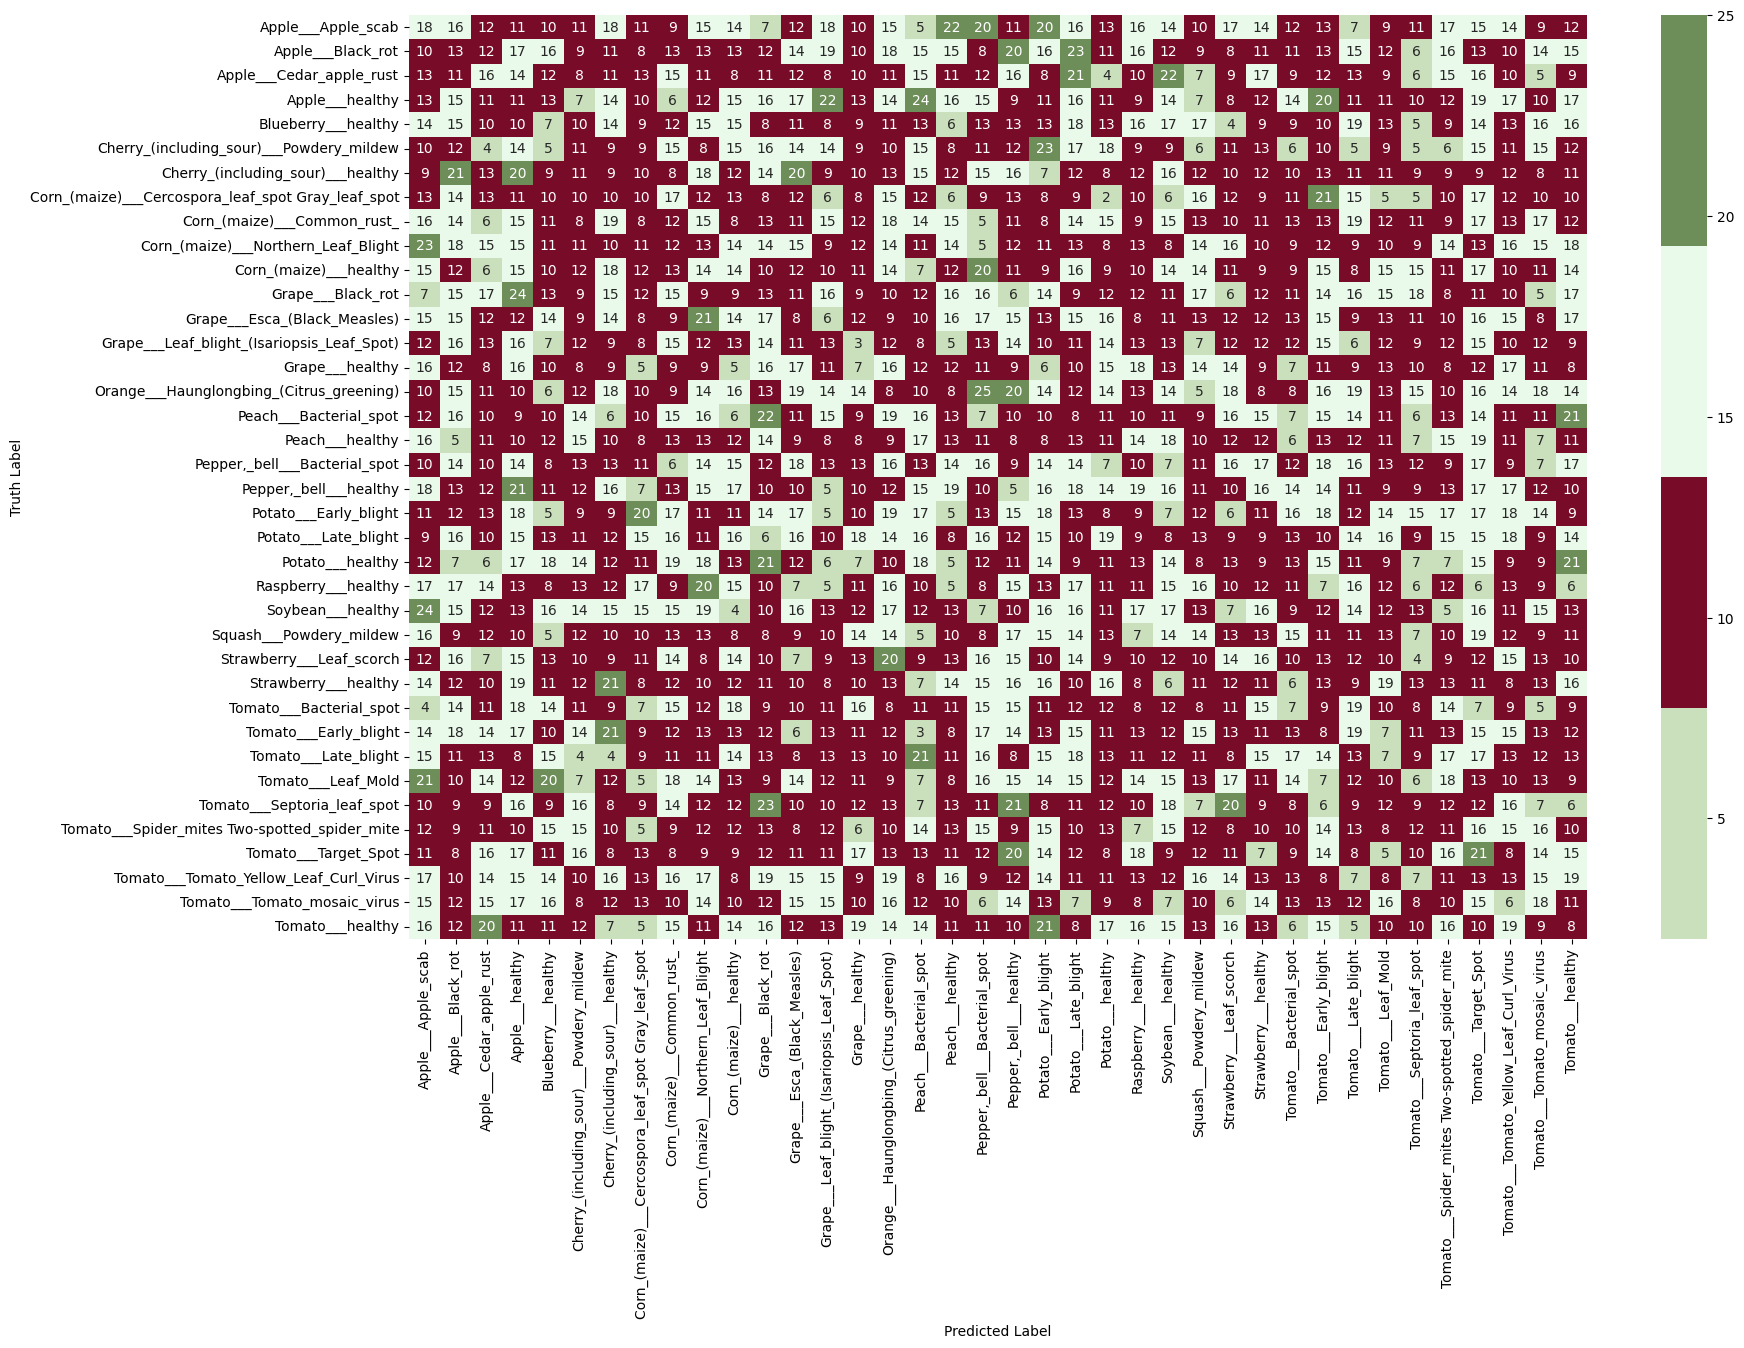

In [32]:
cm = confusion_matrix(valid_gen.classes, y_pred)
labels = list(class_dict.keys())
plt.figure(figsize=(19,12))
sns.heatmap(cm, annot=True, fmt='d', cmap=color, xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted Label')
plt.ylabel('Truth Label')
plt.show()


<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     Plotting the training and validation accuracy and loss over epochs

</div>


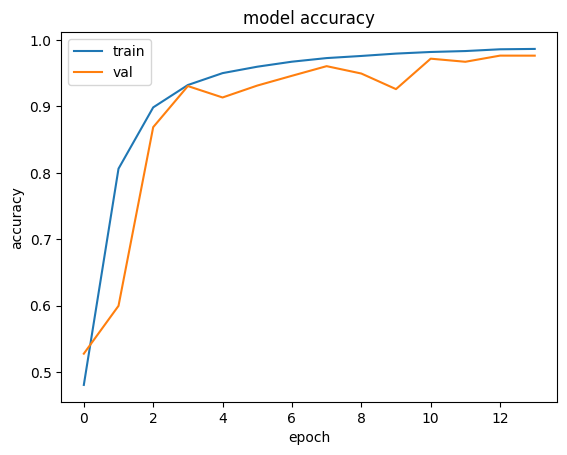

In [34]:
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')

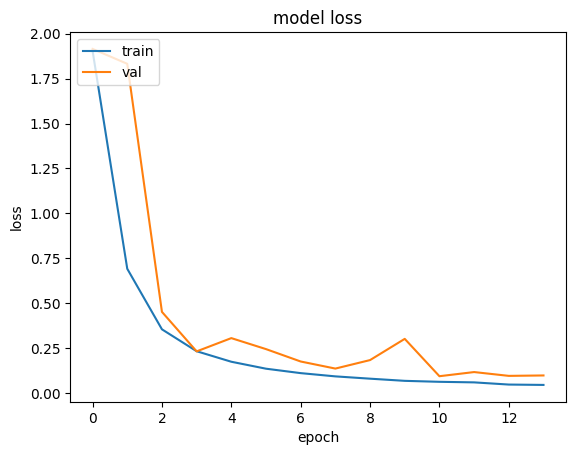

In [35]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')

 
<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     predict the class of an input image and visualize probabilities
</div>



In [40]:
def predict(img_path):

    
    label = list(class_dict.keys())
    plt.figure(figsize=(12, 19))
    img = Image.open(img_path)
    resized_img = img.resize((224, 224))
    img = np.asarray(resized_img)
    img = np.expand_dims(img, axis=0)
    img = img / 255
    predictions = Model.predict(img)
    probs = list(predictions[0])
    labels = label
    plt.subplot(2, 1, 1)
    plt.imshow(resized_img)
    plt.subplot(2, 1, 2)
    bars = plt.barh(labels, probs)
    plt.xlabel('Probability', fontsize=15)
    ax = plt.gca()
    ax.bar_label(bars, fmt = '%.2f')
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


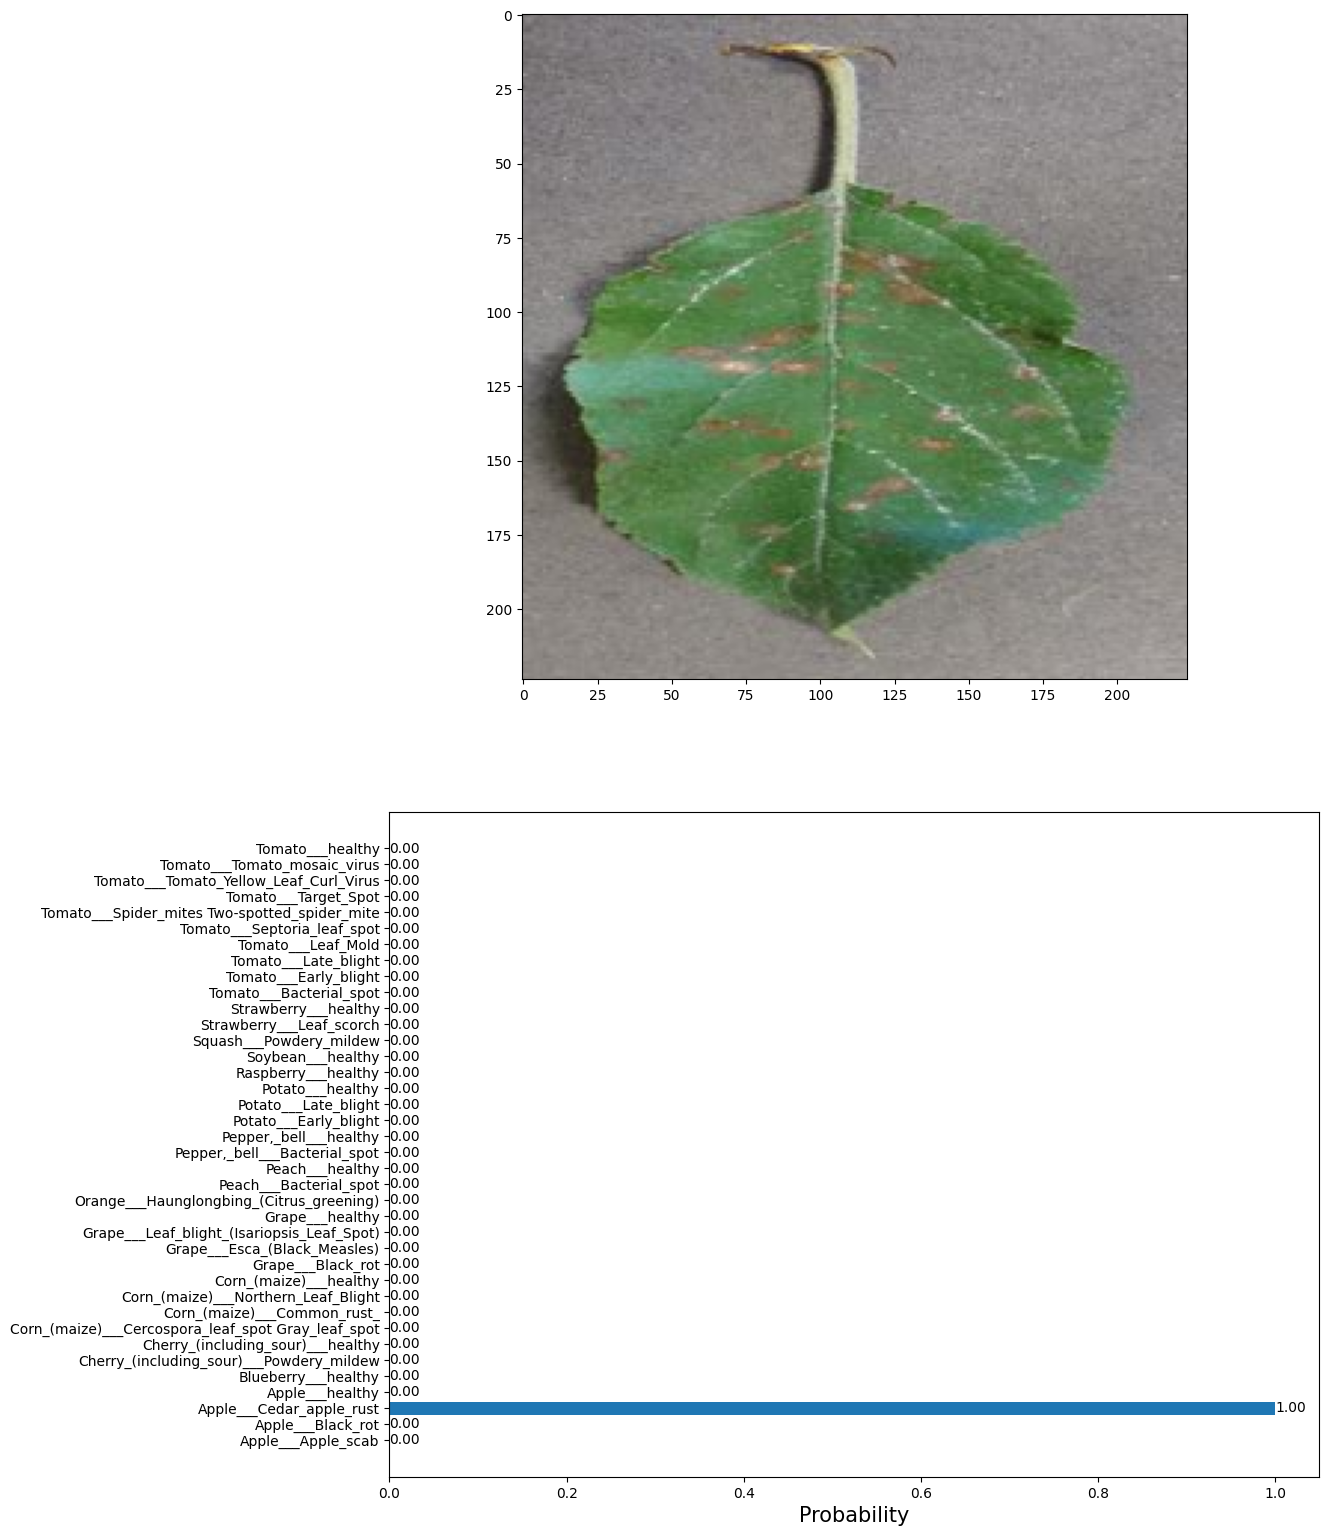

In [41]:
predict('/kaggle/input/new-plant-diseases-dataset/test/test/AppleCedarRust2.JPG')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


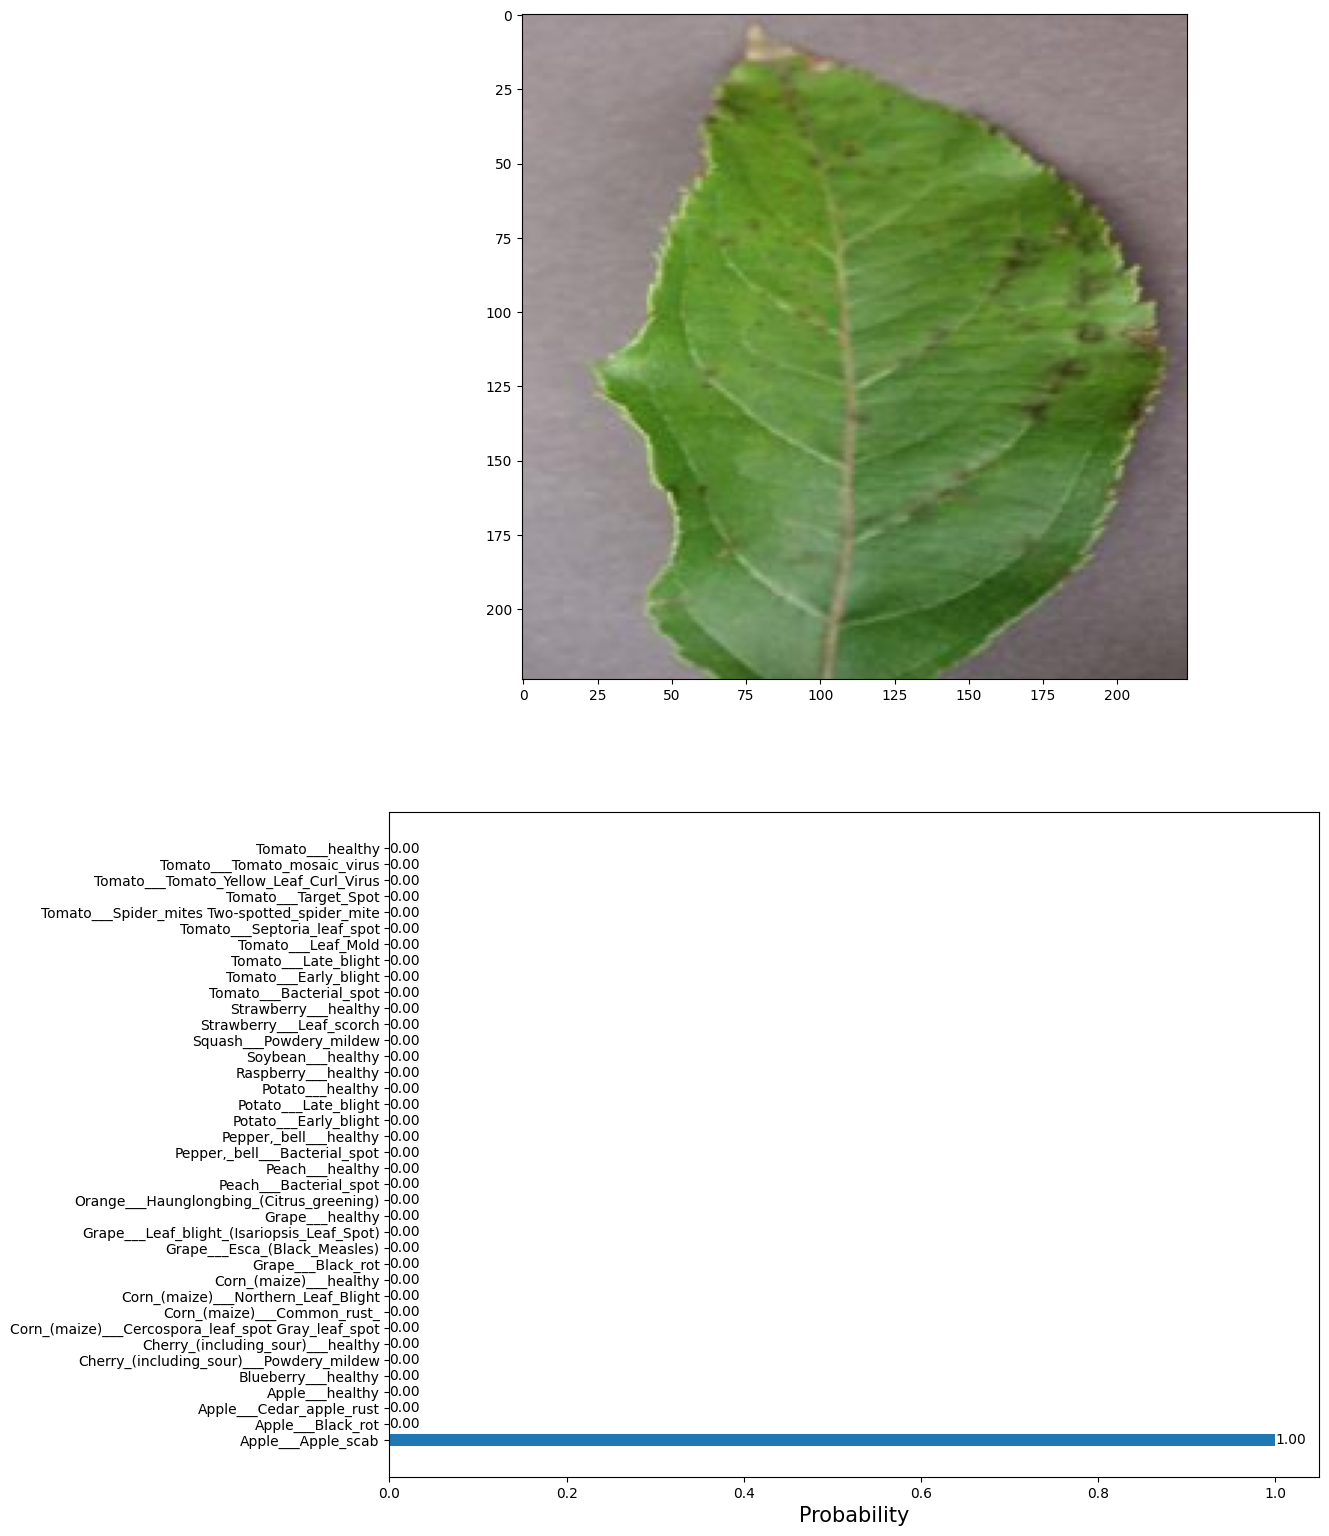

In [42]:
predict('/kaggle/input/new-plant-diseases-dataset/test/test/AppleScab1.JPG')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step


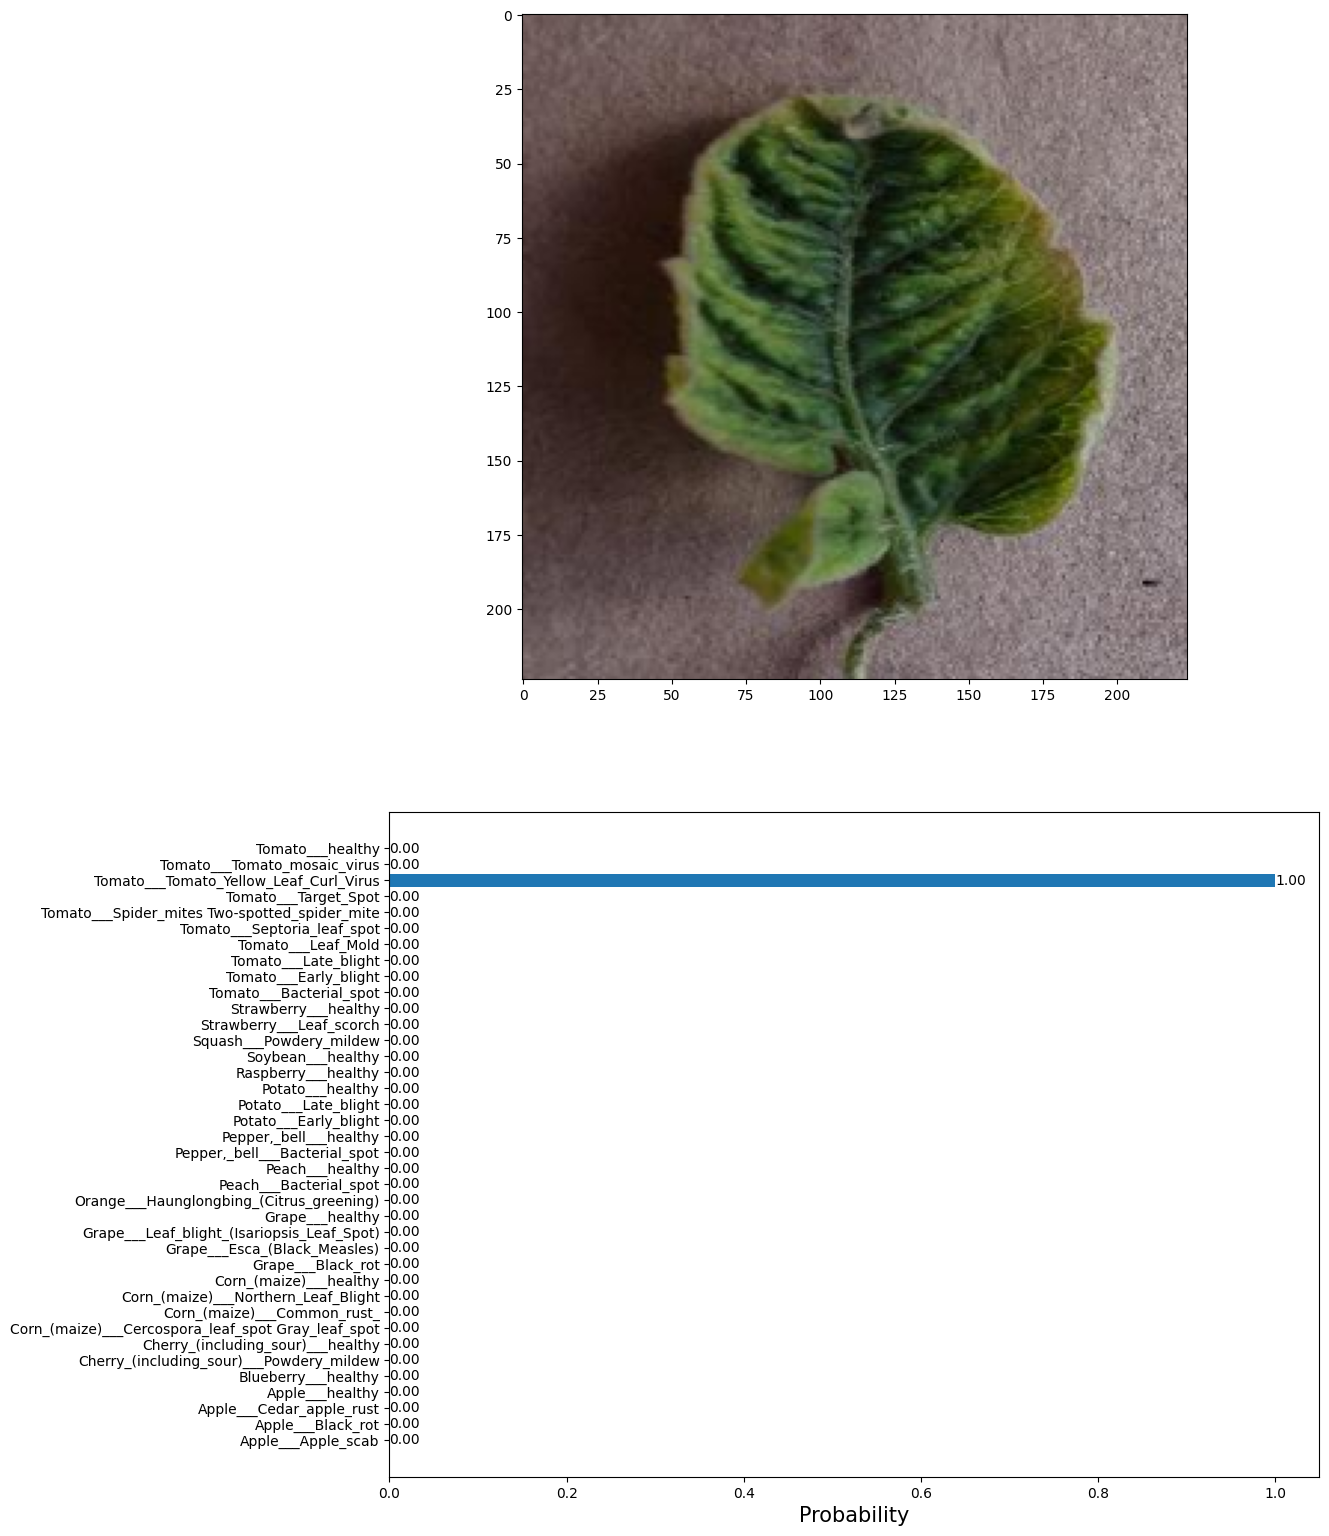

In [43]:
predict('/kaggle/input/new-plant-diseases-dataset/test/test/TomatoYellowCurlVirus2.JPG')


<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     Loading the EfficientNetB3 model pre-trained on ImageNet without the top classification layer 
</div>


In [45]:
base_model = tf.keras.applications.EfficientNetB3(
    include_top=False,
    weights="imagenet",
    input_shape=(imge_size[0],imge_size[1],3),
    pooling='max',
)

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


<div style="background-color: black; color: gold; padding: 10px; 
            font-size: 20px; border-radius: 5px; text-align: center;">
    Building and compiling a Sequential model with a pre-trained EfficientNetB3 base 
</div>


In [48]:
ModelPretrained = Sequential([
    base_model,
    
    Dense(256 , activation='relu'),
    Dropout(0.3),
    Dense(38, activation='softmax')
    
])
ModelPretrained.compile(optimizer=Adamax(learning_rate=0.001), loss='categorical_crossentropy', metrics=['accuracy'])

<div style="background-color: black; color: gold; padding: 10px; 
            font-size: 20px; border-radius: 5px; text-align: center;">
     Training the fine-tuned EfficientNetB3 model with training and validation data
</div>


In [49]:
history_Final = ModelPretrained.fit(
    train_gen, 
    epochs=5, 
    validation_data=valid_gen, 
    verbose=1, 
    
)

Epoch 1/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 1172s 487ms/step - accuracy: 0.7750 - loss: 0.9704 - val_accuracy: 0.9884 - val_loss: 0.0336
Epoch 2/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 992s 450ms/step - accuracy: 0.9782 - loss: 0.0736 - val_accuracy: 0.9921 - val_loss: 0.0287
Epoch 3/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 996s 452ms/step - accuracy: 0.9888 - loss: 0.0415 - val_accuracy: 0.9941 - val_loss: 0.0192
Epoch 4/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 1002s 455ms/step - accuracy: 0.9928 - loss: 0.0259 - val_accuracy: 0.9963 - val_loss: 0.0120
Epoch 5/5
2197/2197 ━━━━━━━━━━━━━━━━━━━━ 1018s 462ms/step - accuracy: 0.9938 - loss: 0.0207 - val_accuracy: 0.9959 - val_loss: 0.0148


<div style="background-color: black; color: gold; padding: 10px; 
            font-size: 20px; border-radius: 5px; text-align: center;">
    Evaluating the fine-tuned EfficientNetB3 model on training and validation datasets 
</div>


In [50]:
print(ModelPretrained.evaluate(train_gen))
print(ModelPretrained.evaluate(valid_gen))

2197/2197 ━━━━━━━━━━━━━━━━━━━━ 817s 372ms/step - accuracy: 0.9979 - loss: 0.0069
[0.007135253865271807, 0.9977949857711792]
550/550 ━━━━━━━━━━━━━━━━━━━━ 198s 360ms/step - accuracy: 0.9952 - loss: 0.0163
[0.017256472259759903, 0.9953334927558899]



<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     Saving the trained CNN model ACC 99.53%
</div>


In [58]:
ModelPretrained.save('Plant_Village_Detection_Model_ACC99.53%.h5')


<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     Generating predictions using the fine-tuned EfficientNetB3 model on validation data 
</div>


In [53]:
preds = ModelPretrained.predict(valid_gen)
y_pred_ModelPretrained = np.argmax(preds, axis=1)

550/550 ━━━━━━━━━━━━━━━━━━━━ 204s 372ms/step


<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
    Plotting a confusion matrix to visualize model performance on validation data

</div>

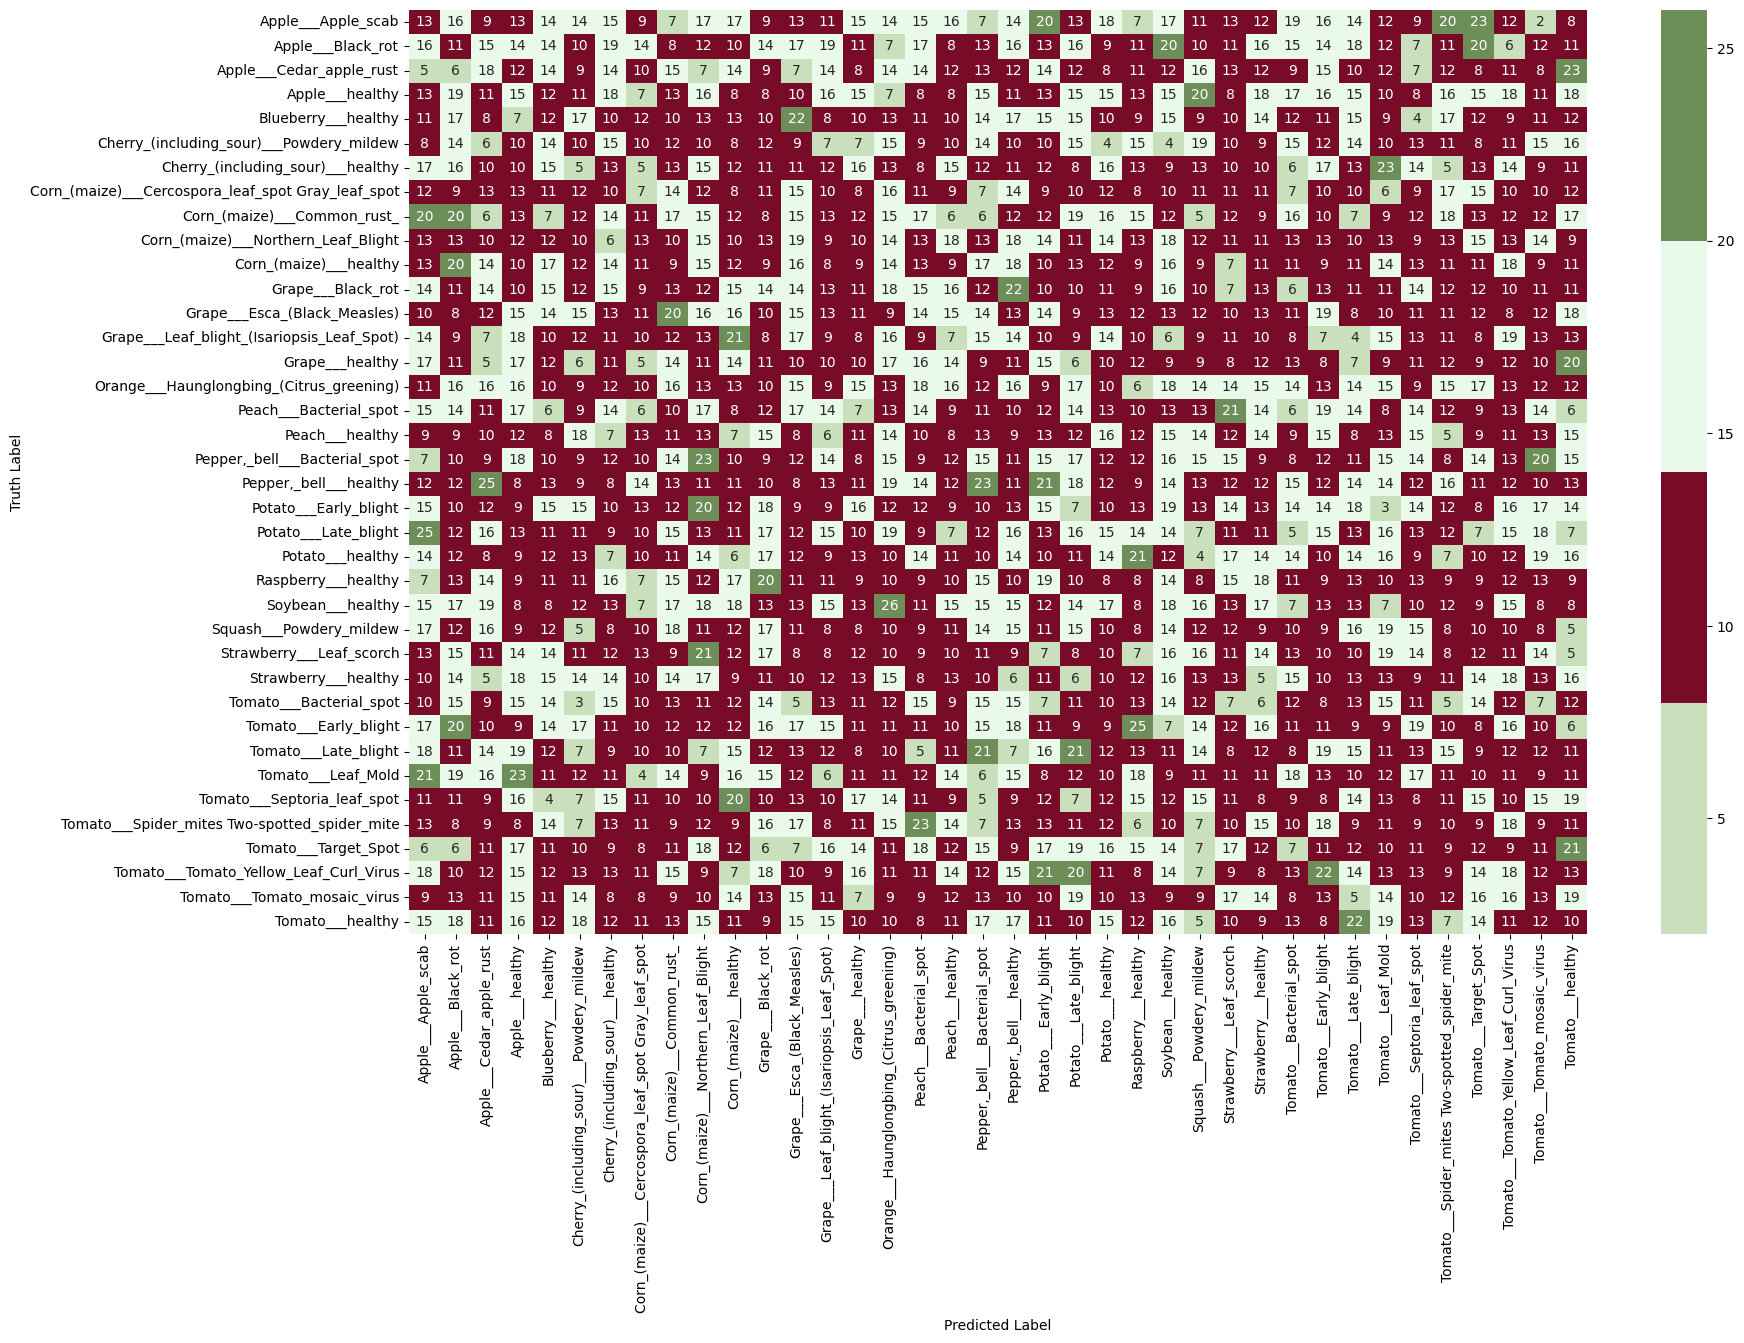

In [54]:
cm = confusion_matrix(valid_gen.classes, y_pred_ModelPretrained)
labels = list(class_dict.keys())
plt.figure(figsize=(19,12))
sns.heatmap(cm, annot=True, fmt='d', cmap=color, xticklabels=labels, yticklabels=labels)
plt.xlabel('Predicted Label')
plt.ylabel('Truth Label')
plt.show()

<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     predict the class of an input image and visualize probabilities
</div>

In [55]:
def predict(img_path):

    
    label = list(class_dict.keys())
    plt.figure(figsize=(12, 19))
    img = Image.open(img_path)
    resized_img = img.resize((224, 224))
    img = np.asarray(resized_img)
    img = np.expand_dims(img, axis=0)
    img = img / 255
    predictions = ModelPretrained.predict(img)
    probs = list(predictions[0])
    labels = label
    plt.subplot(2, 1, 1)
    plt.imshow(resized_img)
    plt.subplot(2, 1, 2)
    bars = plt.barh(labels, probs)
    plt.xlabel('Probability', fontsize=15)
    ax = plt.gca()
    ax.bar_label(bars, fmt = '%.2f')
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 8s 8s/step


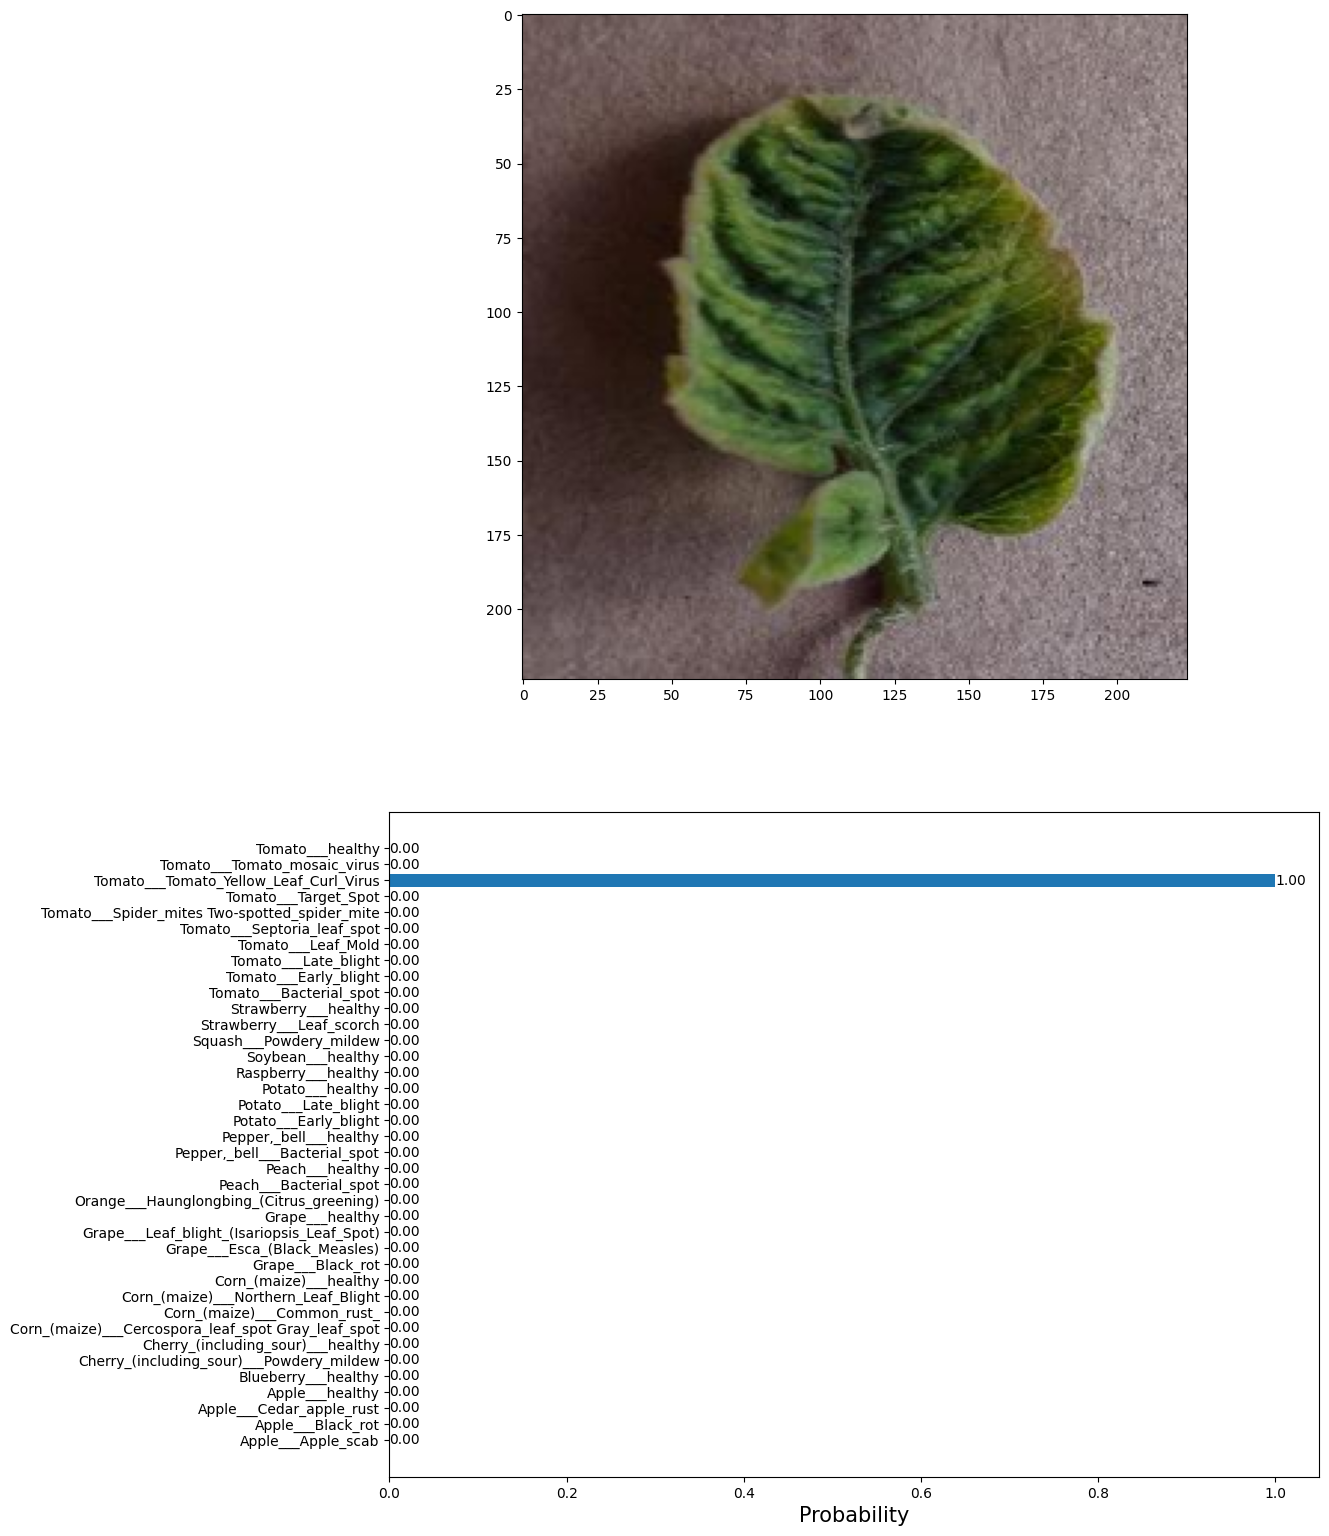

In [56]:
predict('/kaggle/input/new-plant-diseases-dataset/test/test/TomatoYellowCurlVirus2.JPG')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


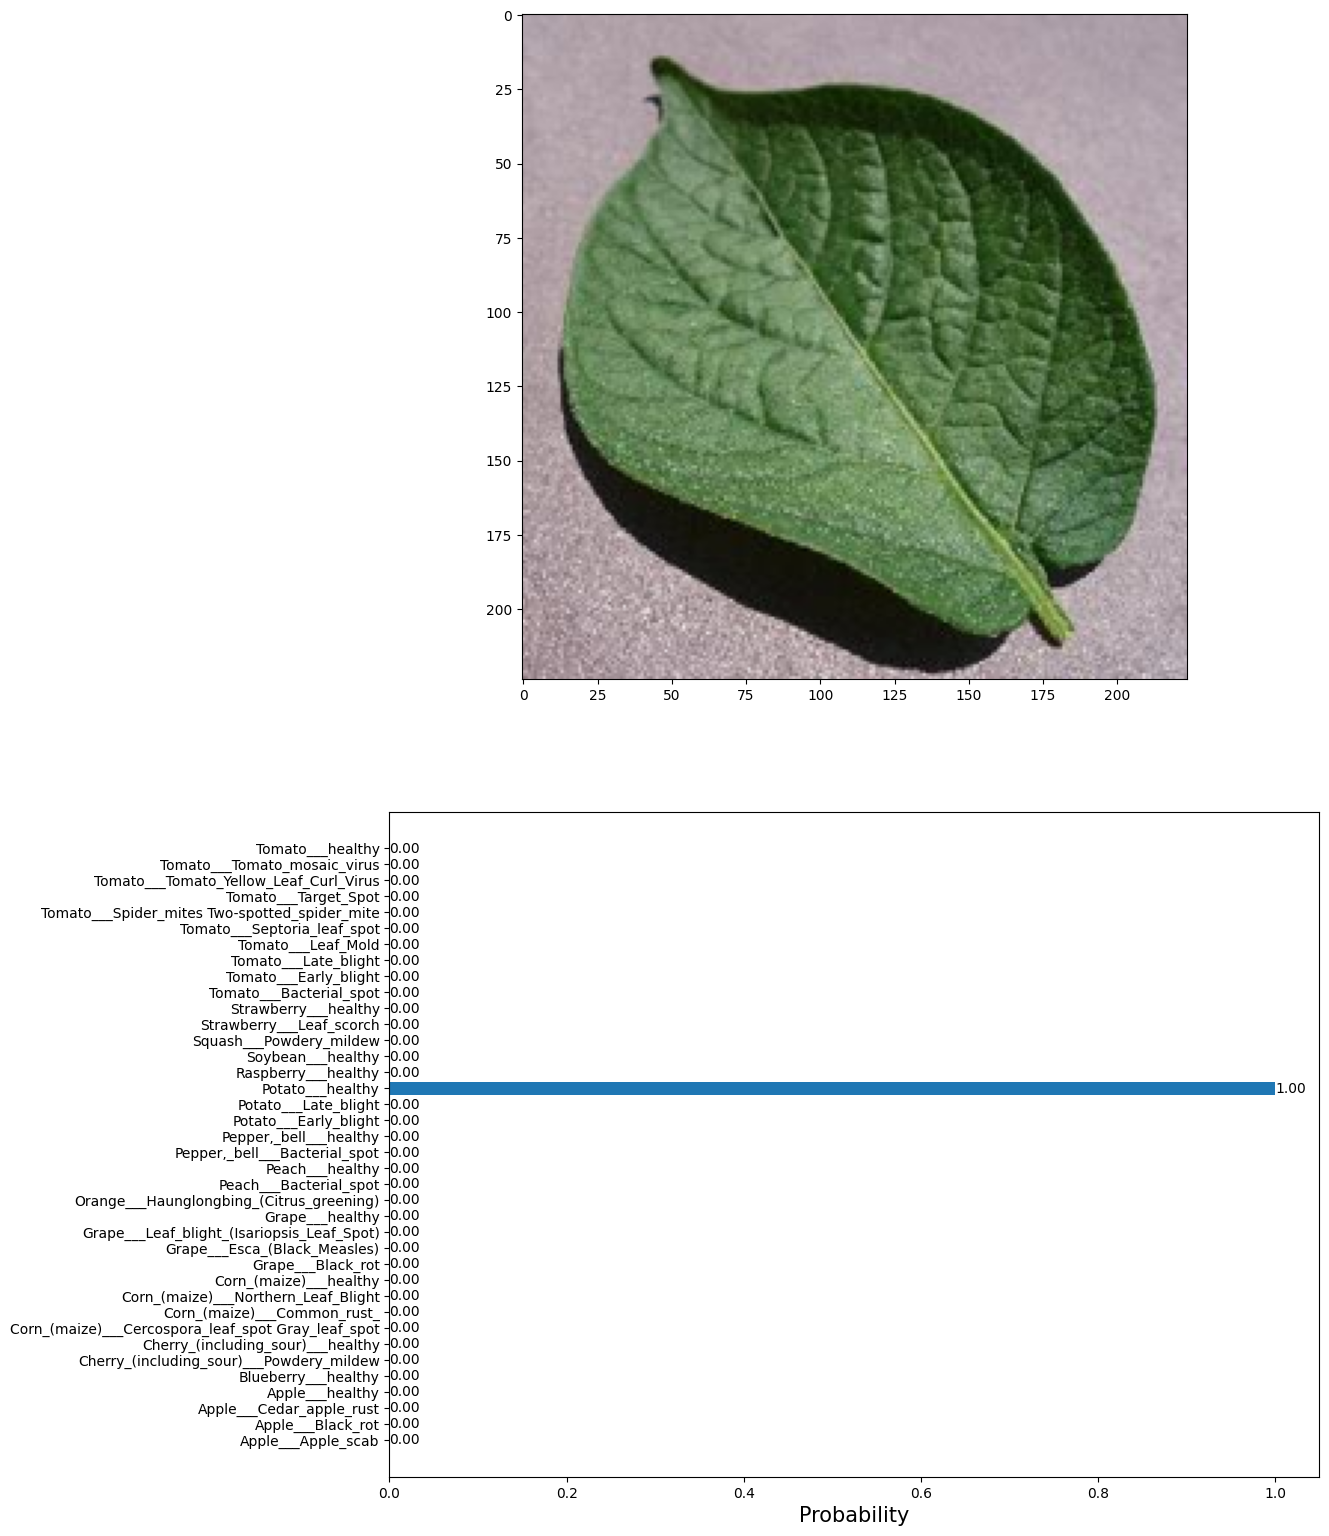

In [71]:
predict('/kaggle/input/new-plant-diseases-dataset/test/test/PotatoHealthy1.JPG')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


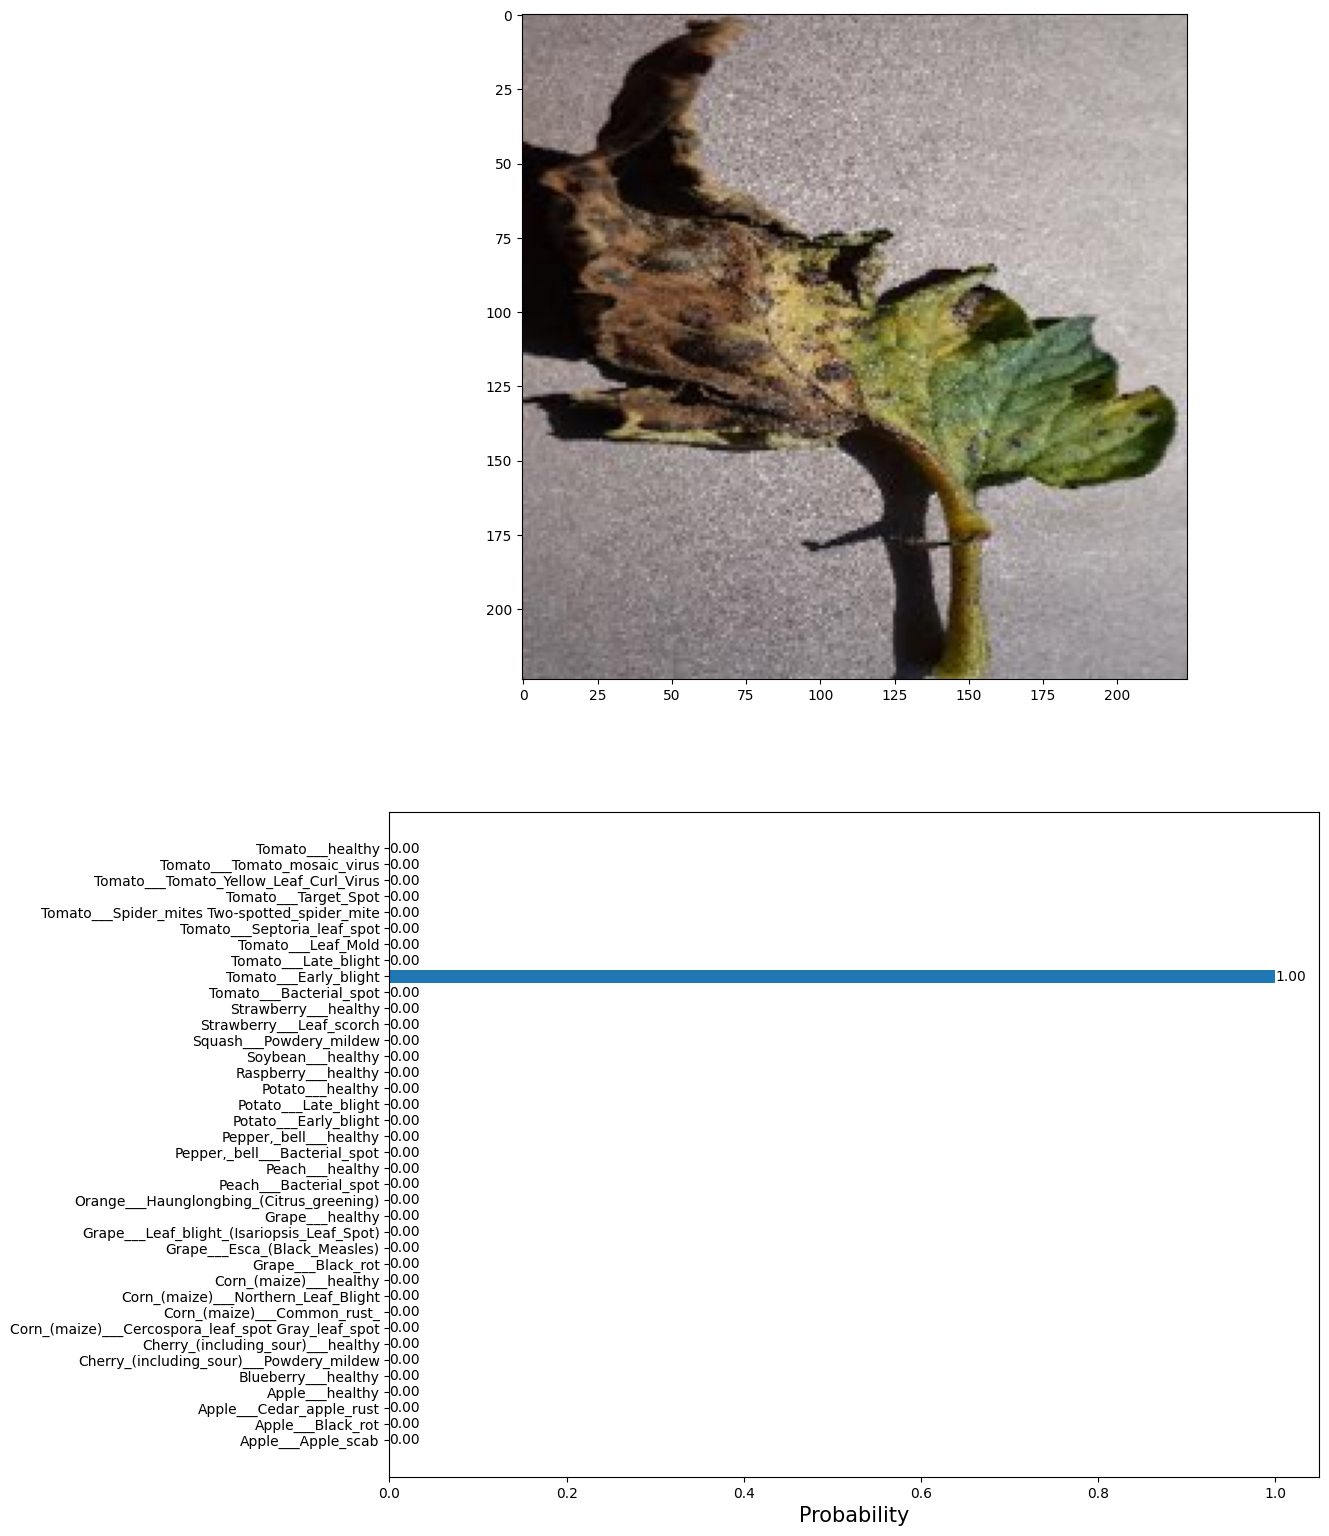

In [78]:
predict('/kaggle/input/new-plant-diseases-dataset/test/test/TomatoEarlyBlight1.JPG')


1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


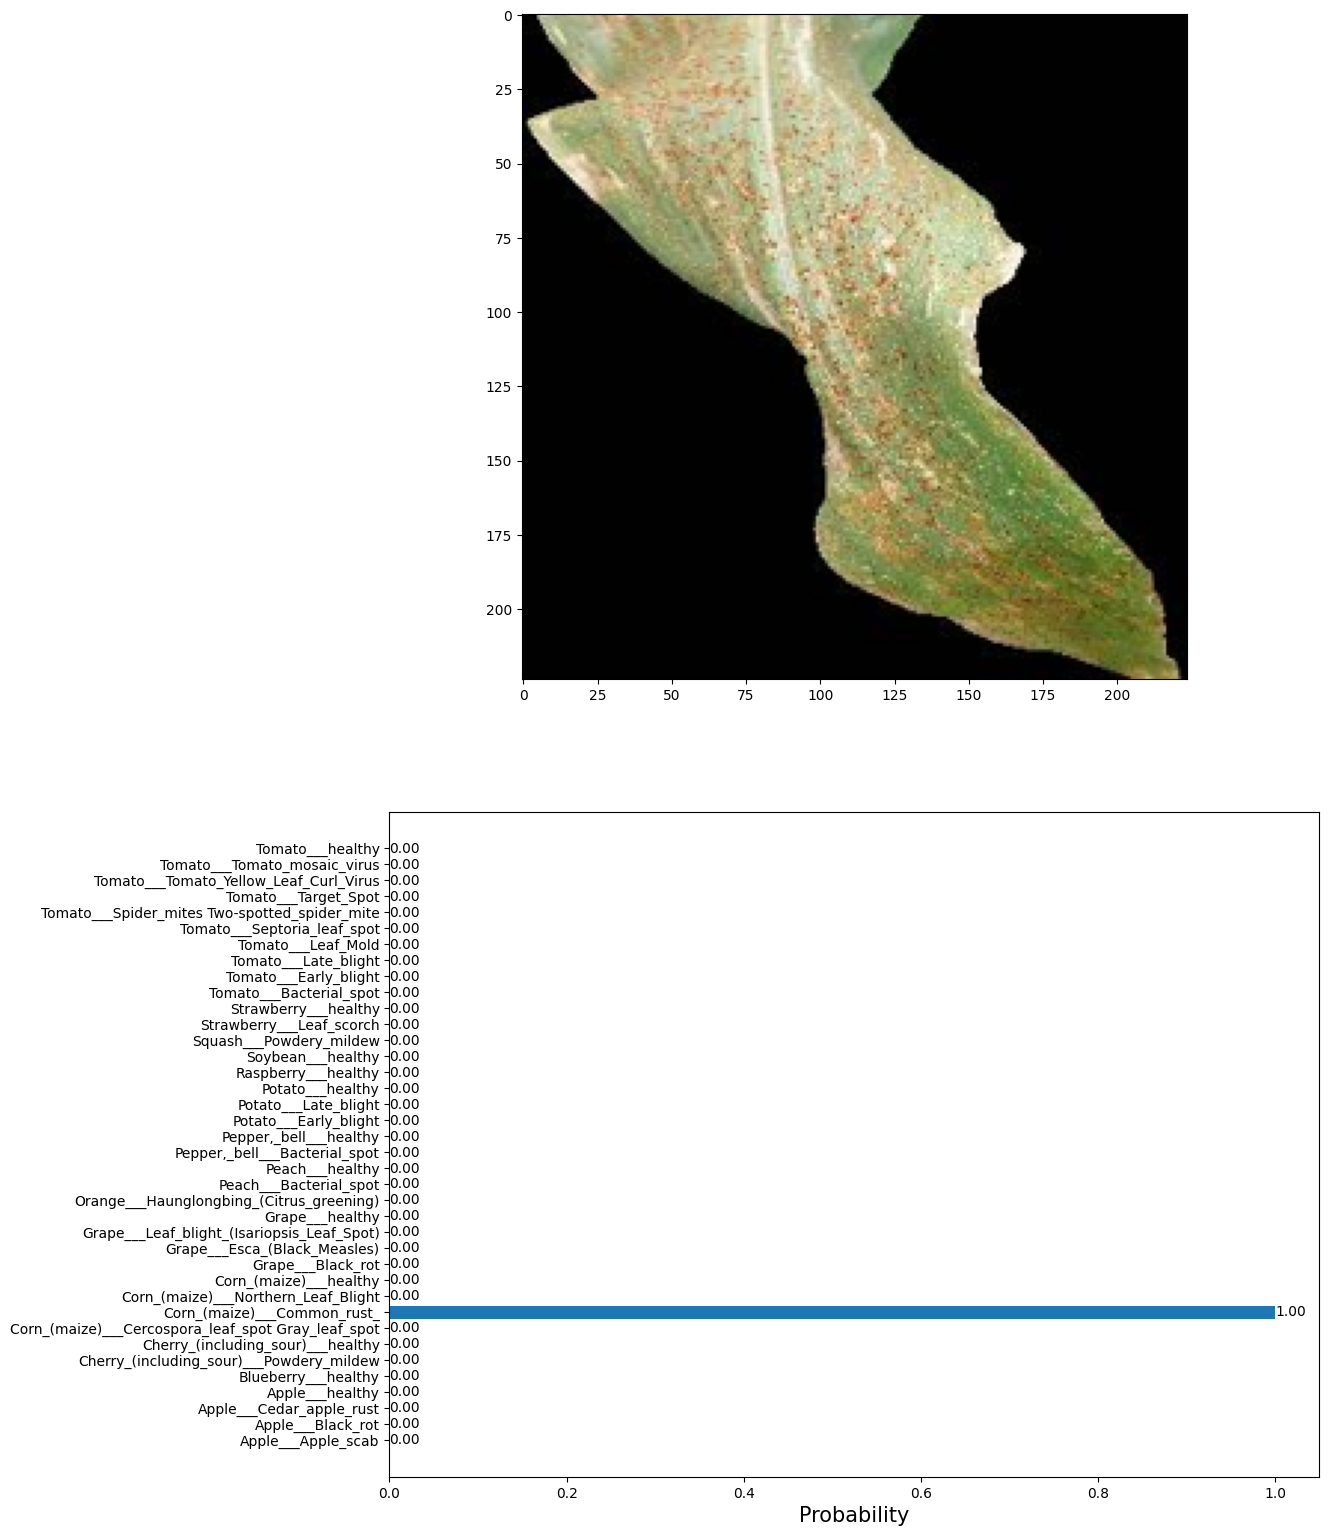

In [79]:
predict('/kaggle/input/new-plant-diseases-dataset/test/test/CornCommonRust3.JPG')




<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 20px; border-radius: 5px;">
     Plotting the training and validation accuracy and loss over epochs

</div>

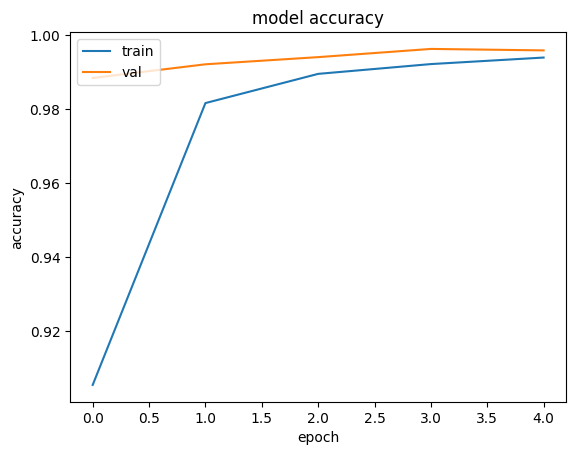

In [60]:
plt.plot(history_Final.history['accuracy'])
plt.plot(history_Final.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')

### Summary

| Model | Validation accuracy | Role |
| --- | --- | --- |
| Baseline CNN | 97.23% | First pass and comparison point |
| **EfficientNetB3 (fine-tuned)** | **99.53%** | The model shipped in Leafwise |

**Where this goes next in the repository**

- Runtime model and contracts: `backend/models/` (start with `MODEL_CARD.md`)
- How the API serves predictions: `docs/architecture.md`
- Run the full stack locally: `docs/getting-started.md`

Confidence thresholds used by the app are provisional pending calibration — see the model card.


<div style="background-color: black; color: gold; padding: 10px; text-align: center; font-size: 30px; border-radius: 5px;">
    Leafwise
    <br>
    <span style="font-size: 16px; color: gray;">A little clarity. A healthier harvest.</span>
    <br>
    <a href="https://github.com/janvibuilds/Leafwise" style="color: gold; font-size: 16px; text-decoration: none;">github.com/janvibuilds/Leafwise</a>
</div>
